# 02 – Data Ingestion & Exploratory Data Analysis

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 2 (Data pipeline) + early Phase 3 (EDA)

### Goals
1. Load the validated ticker list produced by notebook 01  
2. Ingest historical daily OHLCV for the keep-list into **local MongoDB** (idempotent upserts)  
3. Run a structured EDA: missingness, returns, volatility, drawdowns, correlations  
4. Persist key EDA summaries back to MongoDB and to `data/processed/`  

### Prerequisites
- Notebook 01 has been run successfully  
- Local `mongod` is running on `localhost:27017`  
- `data/processed/validated_tickers.csv` exists

In [27]:
# Cell 1 – Imports & setup
from __future__ import annotations

import sys
from pathlib import Path
from datetime import datetime, timedelta
from typing import Any, Dict, List, Optional

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make project root importable
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings, TICKERS, CATEGORIES
from config.tickers import get_primary_category
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json
from src.db.connection import get_client, get_db, close_client
from src.db.collections import ensure_indexes
from src.db.market_data import get_market_data, get_latest_timestamp
from src.db.company_metadata import get_all_company_metadata
from src.db.analysis_results import save_analysis_result
from src.db.refresh_status import get_refresh_status
from src.data_pipeline.ingestion import backfill_universe, daily_update, ingest_ticker
from src.data_pipeline.validators import coverage_report
from src.features.returns import add_returns, cumulative_return
from src.features.volatility import add_volatility
from src.features.technical import add_technical
from src.analysis.eda import run_eda, summary_statistics
from src.analysis.correlation import correlation_matrix, correlation_summary
from src.analysis.drawdown import drawdown_stats, underwater_curve
from src.analysis.comparison import compare_tickers, category_summary

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)

print("Project root :", PROJECT_ROOT)
print("MongoDB URI  :", settings.MONGODB_URI)
print("Database     :", settings.MONGODB_DB_NAME)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket
MongoDB URI  : mongodb://localhost:27017
Database     : tech_fintech_market_intel


In [28]:
## 1. Load validated universe from notebook 01

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)
keep_path = processed_dir / "validated_tickers.csv"

if not keep_path.exists():
    raise FileNotFoundError(
        f"{keep_path} not found. Run notebook 01 first."
    )

keep_df = pd.read_csv(keep_path)
VALIDATED_TICKERS = keep_df["ticker"].str.upper().tolist()
print(f"Loaded {len(VALIDATED_TICKERS)} validated tickers")
display(keep_df.head(10))
print("\nBy category:")
display(keep_df.groupby("category").size().rename("count").to_frame())

Loaded 38 validated tickers


,ticker,category,n_rows,first_ts,last_ts,info_name
0,ANET,Cloud and enterprise infrastructure,1255,2021-10-11 00:00:00,2026-10-09 00:00:00,"Arista Networks, Inc."
1,CSCO,Cloud and enterprise infrastructure,1255,2021-10-11 00:00:00,2026-10-09 00:00:00,"Cisco Systems, Inc."
2,DELL,Cloud and enterprise infrastructure,1255,2021-10-11 00:00:00,2026-10-09 00:00:00,Dell Technologies Inc.
3,HPE,Cloud and enterprise infrastructure,1255,2021-10-11 00:00:00,2026-10-09 00:00:00,Hewlett Packard Enterprise Company
4,IBM,Cloud and enterprise infrastructure,1255,2021-10-11 00:00:00,2026-10-09 00:00:00,International Business Machines Corporation
5,ORCL,Cloud and enterprise infrastructure,1255,2021-10-11 00:00:00,2026-10-09 00:00:00,Oracle Corporation
6,CRWD,"Data, AI, and digital infrastructure software",1255,2021-10-11 00:00:00,2026-10-09 00:00:00,"CrowdStrike Holdings, Inc."
7,DDOG,"Data, AI, and digital infrastructure software",1255,2021-10-11 00:00:00,2026-10-09 00:00:00,"Datadog, Inc."
8,MDB,"Data, AI, and digital infrastructure software",1255,2021-10-11 00:00:00,2026-10-09 00:00:00,"MongoDB, Inc."
9,NET,"Data, AI, and digital infrastructure software",1255,2021-10-11 00:00:00,2026-10-09 00:00:00,"Cloudflare, Inc."



By category:


,count
category,
Cloud and enterprise infrastructure,6
"Data, AI, and digital infrastructure software",6
Enterprise software and developer platforms,8
Fintech and digital financial infrastructure,5
Major technology platforms,6
Semiconductors and chip design,7


In [29]:
## 2. Ensure MongoDB indexes & connectivity

client = get_client()
db = get_db()
ensure_indexes(db)
print("MongoDB reachable. Collections:", db.list_collection_names())

2026-10-12 11:14:50 | INFO     | src.db.collections | All MongoDB indexes ensured.
MongoDB reachable. Collections: ['refresh_status', 'market_data', 'company_metadata', 'analysis_results', 'predictions', 'model_evaluations']


## 3. Historical backfill (idempotent)

We pull up to 5 years of daily bars for every validated ticker and upsert them  
into the `market_data` collection. Re-running this cell is safe – existing  
keys are updated, not duplicated.

In [30]:
# For a full run leave BACKFILL = True.
# Set to False if you only want to inspect already-ingested data.
BACKFILL = True
HISTORY_PERIOD = "5y"

if BACKFILL:
    logger.info("Starting backfill for %d tickers (period=%s)", len(VALIDATED_TICKERS), HISTORY_PERIOD)
    backfill_summary = backfill_universe(
        tickers=VALIDATED_TICKERS,
        period=HISTORY_PERIOD,
        interval="1d",
    )
    summary_series = pd.Series(backfill_summary, name="records_written")
    print("\nBackfill finished – records written per ticker:")
    display(summary_series.sort_values(ascending=False).to_frame())
    print(f"\nTotal records written: {summary_series.sum()}")
else:
    print("BACKFILL=False – skipping ingestion.")
    backfill_summary = {}

2026-10-12 11:14:50 | INFO     | __main__ | Starting backfill for 38 tickers (period=5y)
2026-10-12 11:14:50 | INFO     | src.data_pipeline.ingestion | Starting backfill for 38 tickers (period=5y)
2026-10-12 11:14:50 | INFO     | src.data_pipeline.ingestion | [1/38] Backfilling ANET
2026-10-12 11:14:50 | INFO     | src.data_pipeline.ingestion | Ingesting ANET (interval=1d)
2026-10-12 11:14:52 | INFO     | src.data_pipeline.ingestion | Ingested ANET → 1255 records written
2026-10-12 11:14:52 | INFO     | src.data_pipeline.ingestion | [2/38] Backfilling CSCO
2026-10-12 11:14:52 | INFO     | src.data_pipeline.ingestion | Ingesting CSCO (interval=1d)
2026-10-12 11:14:54 | INFO     | src.data_pipeline.ingestion | Ingested CSCO → 1255 records written
2026-10-12 11:14:54 | INFO     | src.data_pipeline.ingestion | [3/38] Backfilling DELL
2026-10-12 11:14:54 | INFO     | src.data_pipeline.ingestion | Ingesting DELL (interval=1d)
2026-10-12 11:14:56 | INFO     | src.data_pipeline.ingestion | Ing

,records_written
ANET,1255
CSCO,1255
DELL,1255
HPE,1255
IBM,1255
ORCL,1255
CRWD,1255
DDOG,1255
MDB,1255
NET,1255



Total records written: 47690


## 4. Coverage report after ingestion

In [31]:
cov = coverage_report(tickers=VALIDATED_TICKERS, interval="1d")
print(f"Tickers with data : {cov['tickers_with_data']} / {cov['total_tickers']}")
print(f"Missing tickers   : {cov['missing_tickers']}")
print("\nRefresh status summary:", cov["refresh_status_summary"])

# Per-ticker detail
coverage_rows = []
for t, info in cov["per_ticker"].items():
    coverage_rows.append({
        "ticker": t,
        "category": get_primary_category(t),
        "n_bars": info["count"],
        "first_ts": info["first_ts"],
        "last_ts": info["last_ts"],
        "gaps_estimate": info["gaps_estimate"],
    })
coverage_df = pd.DataFrame(coverage_rows).sort_values("n_bars")
display(coverage_df)

2026-10-12 11:15:54 | INFO     | src.data_pipeline.validators | Coverage report: 38/38 tickers have data (1d)
Tickers with data : 38 / 38
Missing tickers   : []

Refresh status summary: {'tracked': 38, 'success': 38, 'failed': 0}


,ticker,category,n_bars,first_ts,last_ts,gaps_estimate
0,ANET,Cloud and enterprise infrastructure,1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
1,CSCO,Cloud and enterprise infrastructure,1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
2,DELL,Cloud and enterprise infrastructure,1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
3,HPE,Cloud and enterprise infrastructure,1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
4,IBM,Cloud and enterprise infrastructure,1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
5,ORCL,Cloud and enterprise infrastructure,1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
6,CRWD,"Data, AI, and digital infrastructure software",1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
7,DDOG,"Data, AI, and digital infrastructure software",1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
8,MDB,"Data, AI, and digital infrastructure software",1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4
9,NET,"Data, AI, and digital infrastructure software",1255,2021-10-11T00:00:00,2026-10-09T00:00:00,4


In [32]:
## 5. Helper – load a single ticker as a clean DataFrame

def load_ticker_df(
    ticker: str,
    interval: str = "1d",
    start: Optional[datetime] = None,
    end: Optional[datetime] = None,
) -> pd.DataFrame:
    """Fetch OHLCV from MongoDB and return a tidy DataFrame indexed by timestamp."""
    rows = get_market_data(ticker, interval=interval, start=start, end=end)
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.set_index("timestamp").sort_index()
    # Keep only the classic OHLCV columns + adj_close if present
    cols = [c for c in ["open", "high", "low", "close", "volume", "adj_close"] if c in df.columns]
    return df[cols].astype(float)


# Quick smoke-test
sample_ticker = VALIDATED_TICKERS[0]
sample_df = load_ticker_df(sample_ticker)
print(f"Sample ({sample_ticker}): {len(sample_df)} rows")
display(sample_df.tail(3))

Sample (ANET): 1255 rows


,open,high,low,close,volume
timestamp,,,,,
2026-10-07,211.300003,217.317993,209.130005,215.830002,4995900.0
2026-10-08,213.494995,217.320007,209.509995,210.970001,4875100.0
2026-10-09,215.380005,217.410004,213.651001,216.740005,4329200.0


In [33]:
## 6. Missingness & basic quality checks

missing_report = []
for t in VALIDATED_TICKERS:
    df = load_ticker_df(t)
    if df.empty:
        missing_report.append({"ticker": t, "n_rows": 0, "pct_missing_close": 100.0})
        continue
    pct_missing = df["close"].isna().mean() * 100
    missing_report.append({
        "ticker": t,
        "n_rows": len(df),
        "pct_missing_close": round(pct_missing, 3),
        "first": str(df.index.min().date()),
        "last": str(df.index.max().date()),
    })

missing_df = pd.DataFrame(missing_report).sort_values("pct_missing_close", ascending=False)
print("Tickers with any missing close prices:")
display(missing_df[missing_df["pct_missing_close"] > 0])
print("\nOverall missingness summary:")
display(missing_df["pct_missing_close"].describe().to_frame())

Tickers with any missing close prices:


,ticker,n_rows,pct_missing_close,first,last



Overall missingness summary:


,pct_missing_close
count,38.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


## 7. Single-ticker deep dive (example)

Pick one liquid name (default = first validated ticker) and compute  
returns, volatility, technicals and drawdown statistics.

In [34]:
# =============================================================================
# Safe single-ticker EDA cell
# =============================================================================
FOCUS_TICKER = VALIDATED_TICKERS[0]
print(f"Focus ticker: {FOCUS_TICKER} ({get_primary_category(FOCUS_TICKER)})")

df = load_ticker_df(FOCUS_TICKER)
if df.empty:
    raise RuntimeError(f"No data for {FOCUS_TICKER}")

df = add_returns(df)
df = add_volatility(df)
df = add_technical(df)

stats = summary_statistics(df)
print("\nSummary statistics:")
display(pd.Series(stats).to_frame("value"))

dd_stats = drawdown_stats(df["close"])
print("\nDrawdown statistics:")
display(pd.Series({k: v for k, v in dd_stats.items() if k != "top_drawdowns"}).to_frame("value"))

# Build EDA document
eda_doc = run_eda(df, FOCUS_TICKER)

# Extra safety – stringify keys one more time in the notebook itself
def _stringify(obj):
    if isinstance(obj, dict):
        return {str(k): _stringify(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [_stringify(i) for i in obj]
    if hasattr(obj, "item"):
        try:
            return obj.item()
        except Exception:
            pass
    return obj

eda_doc = _stringify(eda_doc)

# Now save
from src.db.analysis_results import save_analysis_result
save_analysis_result(eda_doc)
print(f"\nEDA document saved for {FOCUS_TICKER}")

Focus ticker: ANET (Cloud and enterprise infrastructure)

Summary statistics:


,value
n_obs,1255
start_date,2021-10-11T00:00:00
end_date,2026-10-09T00:00:00
last_price,216.740005
mean_return,0.002243
std_return,0.030762
skew,0.117491
kurtosis,6.907333
min_return,-0.223504
max_return,0.203882



Drawdown statistics:


,value
max_drawdown,-0.50416
max_drawdown_date,2025-04-04T00:00:00
avg_drawdown,-0.115861
median_drawdown,-0.086273
n_episodes,58
avg_recovery_days,28.172414
max_recovery_days,435



EDA document saved for ANET


c:\Users\hp\Documents\GitHub\BeneathTheMarket\src\analysis\eda.py:71: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample("M")


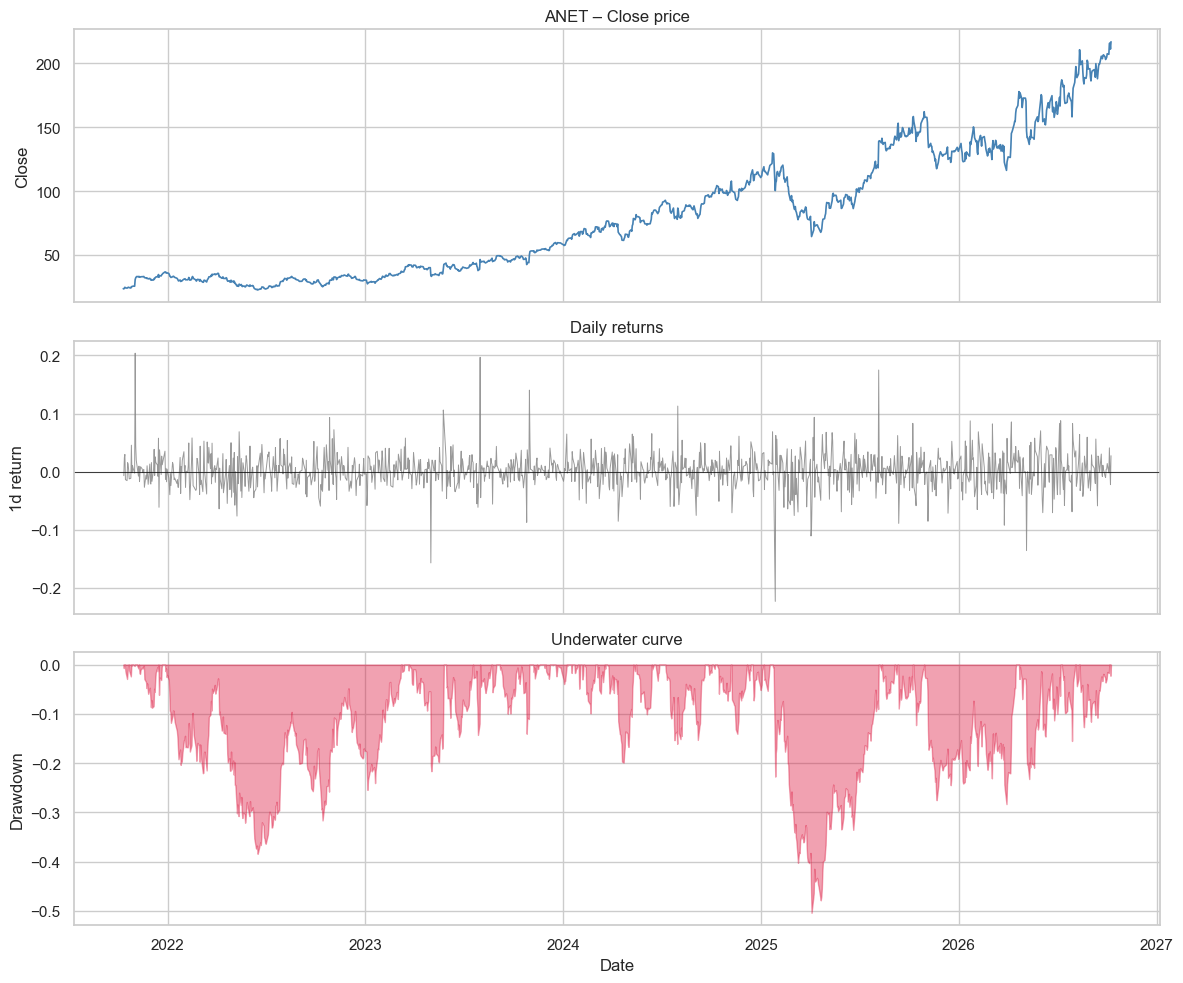

In [35]:
## 8. Visual – price, returns, underwater curve

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Price
axes[0].plot(df.index, df["close"], color="steelblue", lw=1.2)
axes[0].set_ylabel("Close")
axes[0].set_title(f"{FOCUS_TICKER} – Close price")

# Daily returns
axes[1].plot(df.index, df["ret_1d"], color="gray", lw=0.7, alpha=0.8)
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_ylabel("1d return")
axes[1].set_title("Daily returns")

# Underwater curve
uw = underwater_curve(df["close"])
axes[2].fill_between(uw.index, uw, 0, color="crimson", alpha=0.4)
axes[2].set_ylabel("Drawdown")
axes[2].set_title("Underwater curve")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [36]:
## 9. Cross-sectional comparison (all validated tickers)

price_dict: Dict[str, pd.Series] = {}
for t in VALIDATED_TICKERS:
    d = load_ticker_df(t)
    if not d.empty:
        price_dict[t] = d["close"]

print(f"Price series collected for {len(price_dict)} tickers")

comparison = compare_tickers(
    price_dict,
    windows=[21, 63, 252],
)
print("\nCross-ticker comparison (head):")
display(comparison.head(10))

# Category aggregates
print("\nCategory summary – 63-day total return:")
display(category_summary(comparison, metric="total_return_63d"))

Price series collected for 38 tickers

Cross-ticker comparison (head):


,category,last_price,n_obs,total_return_21d,vol_21d,sharpe_21d,total_return_63d,vol_63d,sharpe_63d,total_return_252d,vol_252d,sharpe_252d,max_drawdown
ticker,,,,,,,,,,,,,
ANET,Cloud and enterprise infrastructure,216.740005,1255,0.146833,0.380939,4.511604,0.196467,0.470413,1.757937,0.377351,0.534022,0.867072,-0.504160
CSCO,Cloud and enterprise infrastructure,118.389999,1255,0.106189,0.355603,3.582422,-0.003363,0.340225,0.129663,0.714514,0.350074,1.716504,-0.366751
DELL,Cloud and enterprise infrastructure,586.059998,1255,0.156804,0.633845,3.061523,0.374420,0.792409,1.991203,2.607416,0.746188,2.074813,-0.595877
HPE,Cloud and enterprise infrastructure,73.459999,1255,0.333680,0.718123,5.183975,0.558971,0.632811,3.125368,1.867508,0.577483,2.110244,-0.483578
IBM,Cloud and enterprise infrastructure,227.130005,1255,-0.029442,0.320259,-0.966095,-0.211800,0.598695,-1.250097,-0.194933,0.487958,-0.188177,-0.374996
ORCL,Cloud and enterprise infrastructure,141.399994,1255,-0.072035,0.468666,-1.687949,0.078934,0.547960,0.822581,-0.502683,0.568404,-0.945556,-0.645781
CRWD,"Data, AI, and digital infrastructure software",275.040009,1255,0.316863,0.613078,5.701954,0.463679,0.723257,2.450152,1.157388,0.549646,1.669065,-0.676922
DDOG,"Data, AI, and digital infrastructure software",293.260010,1255,0.322659,0.392072,8.798153,0.126883,0.663697,1.059571,0.786863,0.695121,1.167994,-0.681064
MDB,"Data, AI, and digital infrastructure software",385.929993,1255,0.032257,0.807937,0.890544,0.141906,0.732389,1.101413,0.181009,0.703114,0.589845,-0.765226



Category summary – 63-day total return:


,total_return_63d_mean,total_return_63d_median,total_return_63d_std,total_return_63d_count
category,,,,
"Data, AI, and digital infrastructure software",0.342047,0.356117,0.185812,6
Enterprise software and developer platforms,0.296061,0.220812,0.373442,8
Cloud and enterprise infrastructure,0.165605,0.137701,0.274878,6
Major technology platforms,0.089941,0.061486,0.147018,6
Fintech and digital financial infrastructure,0.070875,0.072645,0.084351,5
Semiconductors and chip design,0.033802,0.015322,0.085778,7


Correlation matrix (representative subset):


,AAPL,NVDA,ORCL,TEAM,PYPL,PLTR
AAPL,1.00,0.47,0.24,0.36,0.40,0.36
NVDA,0.47,1.00,0.42,0.33,0.36,0.47
ORCL,0.24,0.42,1.00,0.27,0.20,0.32
TEAM,0.36,0.33,0.27,1.00,0.39,0.44
PYPL,0.40,0.36,0.20,0.39,1.00,0.34
PLTR,0.36,0.47,0.32,0.44,0.34,1.00


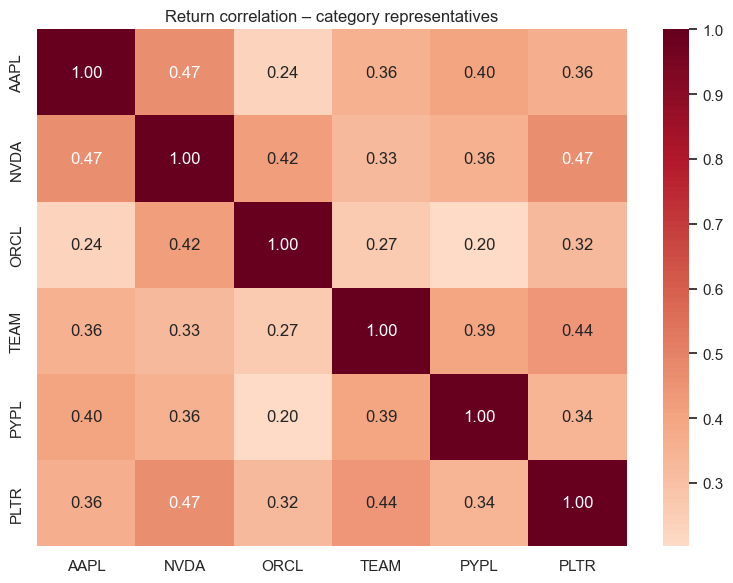


Full-universe average pairwise correlation: 0.379


In [37]:
## 10. Correlation matrix (subset for readability)

# Use a representative subset (one from each category) to keep the matrix readable
subset = []
for cat, tickers in CATEGORIES.items():
    for t in tickers:
        if t in price_dict:
            subset.append(t)
            break

subset_prices = {t: price_dict[t] for t in subset}
corr = correlation_matrix(subset_prices)
print("Correlation matrix (representative subset):")
display(corr.round(2))

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Return correlation – category representatives")
plt.tight_layout()
plt.show()

# Full-universe average correlation
full_corr_summary = correlation_summary(price_dict)
print("\nFull-universe average pairwise correlation: "
      f"{full_corr_summary.get('average_correlation', float('nan')):.3f}")

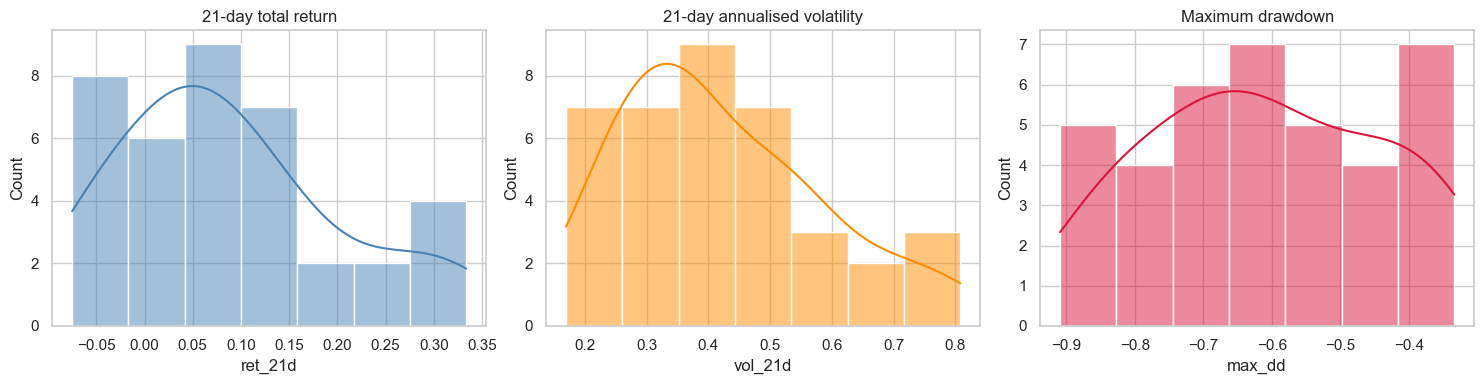

In [38]:
## 11. Distribution of returns & volatility across the universe

ret_21d = []
vol_21d = []
max_dd = []

for t, prices in price_dict.items():
    if len(prices) < 30:
        continue
    r = prices.pct_change(21).iloc[-1]
    v = prices.pct_change().rolling(21).std().iloc[-1] * np.sqrt(252)
    dd = (prices / prices.cummax() - 1).min()
    ret_21d.append({"ticker": t, "ret_21d": r})
    vol_21d.append({"ticker": t, "vol_21d": v})
    max_dd.append({"ticker": t, "max_dd": dd})

ret_df = pd.DataFrame(ret_21d).dropna()
vol_df = pd.DataFrame(vol_21d).dropna()
dd_df = pd.DataFrame(max_dd).dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(ret_df["ret_21d"], kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("21-day total return")
sns.histplot(vol_df["vol_21d"], kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("21-day annualised volatility")
sns.histplot(dd_df["max_dd"], kde=True, ax=axes[2], color="crimson")
axes[2].set_title("Maximum drawdown")
plt.tight_layout()
plt.show()

In [39]:
## 12. Persist EDA artefacts

# 1. Comparison table
comp_path = processed_dir / "cross_ticker_comparison.csv"
comparison.to_csv(comp_path)
print(f"Saved comparison table → {comp_path}")

# 2. Coverage report
cov_path = processed_dir / "coverage_report.json"
save_json(cov, cov_path)
print(f"Saved coverage report → {cov_path}")

# 3. High-level EDA summary for the whole universe
universe_eda = {
    "run_at": utc_now().isoformat(),
    "n_tickers": len(price_dict),
    "avg_pairwise_corr": full_corr_summary.get("average_correlation"),
    "median_21d_return": float(ret_df["ret_21d"].median()) if len(ret_df) else None,
    "median_21d_vol": float(vol_df["vol_21d"].median()) if len(vol_df) else None,
    "median_max_dd": float(dd_df["max_dd"].median()) if len(dd_df) else None,
    "focus_ticker_eda": eda_doc.get("summary") if "eda_doc" in dir() else None,
}
eda_summary_path = processed_dir / "eda_universe_summary.json"
save_json(universe_eda, eda_summary_path)
print(f"Saved universe EDA summary → {eda_summary_path}")

# 4. Also store a compact version in MongoDB
save_analysis_result({
    "analysis_type": "universe_eda",
    "as_of": utc_now(),
    "payload": universe_eda,
})
print("Universe EDA document written to MongoDB")

Saved comparison table → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\cross_ticker_comparison.csv
Saved coverage report → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\coverage_report.json
Saved universe EDA summary → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\eda_universe_summary.json
Universe EDA document written to MongoDB


## 13. Acceptance criteria (Notebook 02)

| Criterion | Status |
|-----------|--------|
| Validated tickers loaded from notebook 01 | Cell 2 |
| Daily history ingested (or already present) | Cell 4 |
| Coverage report generated | Cell 5 |
| Single-ticker EDA + plots | Cells 8-9 |
| Cross-ticker comparison & correlation | Cells 10-11 |
| Artefacts persisted to disk + MongoDB | Cell 13 |


In [40]:
print("Notebook 02 finished successfully.")
# close_client()   # optional

Notebook 02 finished successfully.
